In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Project paths
PROJECT_ROOT = Path(r"C:\cs\Projects\cv-projects\Brain_tumor")

SPLIT_DIR = PROJECT_ROOT / "data" / "processed" / "splits"

TRAIN_CSV = SPLIT_DIR / "train.csv"
VAL_CSV = SPLIT_DIR / "validation.csv"
TEST_CSV = SPLIT_DIR / "test.csv"

# Classes
CLASS_NAMES = [
    "normal",
    "glioma_tumor",
    "meningioma_tumor",
    "pituitary_tumor"
]

# Configuration
IMAGE_SIZE = 256
BATCH_SIZE = 16
RANDOM_SEED = 42

# Device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
print("CUDA available:", torch.cuda.is_available())
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)

Device: cuda
CUDA available: True
Image size: 256
Batch size: 16


In [2]:
train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)
test_df = pd.read_csv(TEST_CSV)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

display(train_df.head())


Training: 1991
Validation: 427
Testing: 427


,image_path,filename,class
0,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,G_506.jpg,glioma_tumor
1,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,M_603.jpg,meningioma_tumor
2,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,M_39.jpg,meningioma_tumor
3,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,P_795.jpg,pituitary_tumor
4,C:\cs\Projects\cv-projects\Brain_tumor\data\ra...,M_185.jpg,meningioma_tumor


In [3]:
# Combine all splits for validation
all_df = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

# Check image paths
missing_paths = [
    path for path in all_df["image_path"]
    if not Path(path).exists()
]

# Check labels
print("Missing image paths:", len(missing_paths))
print("Missing labels:", all_df["class"].isna().sum())

print("\nClass labels:")
print(sorted(all_df["class"].unique()))

print("\nTotal images:", len(all_df))

Missing image paths: 0
Missing labels: 0

Class labels:
['glioma_tumor', 'meningioma_tumor', 'normal', 'pituitary_tumor']

Total images: 2845


Image format: JPEG
Image mode: RGB
Image size: (256, 256)
Array shape: (256, 256, 3)
Pixel range: 0 - 240


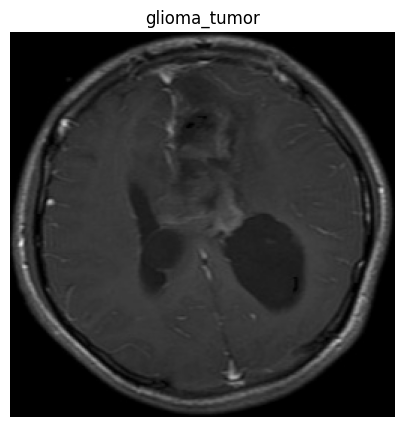

In [4]:
# Load one sample image
sample_path = train_df.iloc[0]["image_path"]

image = Image.open(sample_path)

print("Image format:", image.format)
print("Image mode:", image.mode)
print("Image size:", image.size)

# Convert to RGB
image = image.convert("RGB")

# Convert to NumPy array
image_array = np.array(image)

print("Array shape:", image_array.shape)
print("Pixel range:", image_array.min(), "-", image_array.max())

# Display image
plt.figure(figsize=(5, 5))
plt.imshow(image_array)
plt.title(train_df.iloc[0]["class"])
plt.axis("off")
plt.show()

In [5]:
from torchvision import transforms

basic_transform = transforms.ToTensor()

image_tensor = basic_transform(image)

print("Tensor shape:", image_tensor.shape)
print("Tensor dtype:", image_tensor.dtype)
print("Pixel range:", image_tensor.min().item(), "-", image_tensor.max().item())

Tensor shape: torch.Size([3, 256, 256])
Tensor dtype: torch.float32
Pixel range: 0.0 - 0.9411764740943909


In [6]:
from torchvision import transforms

# Training transformations
train_transform = transforms.Compose([
    transforms.RandomRotation(degrees=10),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.05, 0.05)
    ),
    transforms.ToTensor()
])

# Validation and testing transformations
eval_transform = transforms.Compose([
    transforms.ToTensor()
])

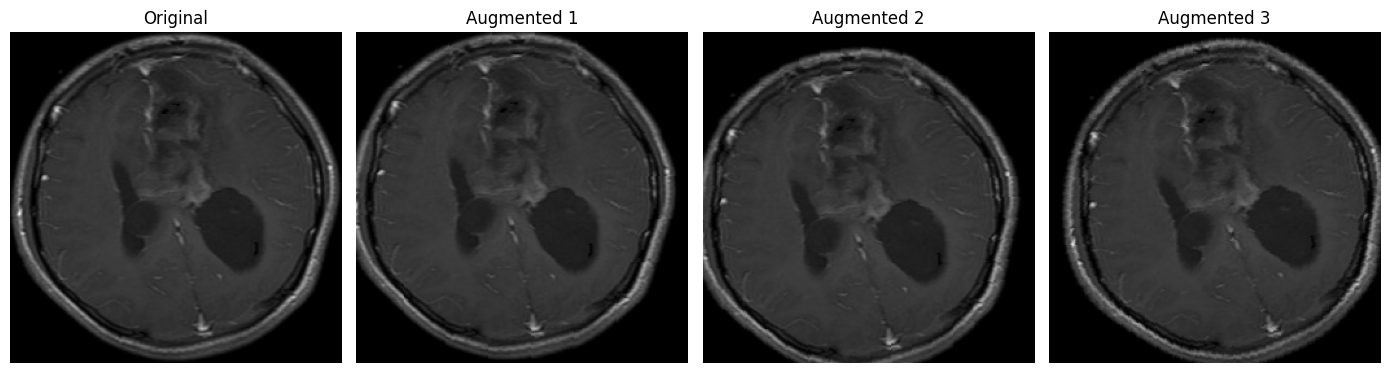

In [7]:
sample_image = Image.open(sample_path).convert("RGB")

fig, axes = plt.subplots(1, 4, figsize=(14, 4))

axes[0].imshow(sample_image)
axes[0].set_title("Original")

for i in range(1, 4):
    augmented_image = train_transform(sample_image)

    axes[i].imshow(augmented_image.permute(1, 2, 0))
    axes[i].set_title(f"Augmented {i}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
train_transform = transforms.Compose([
    transforms.RandomApply([
        transforms.RandomRotation(10)
    ], p=0.5),

    transforms.RandomApply([
        transforms.RandomAffine(
            degrees=0,
            translate=(0.05, 0.05)
        )
    ], p=0.5),

    transforms.ToTensor()
])

eval_transform = transforms.ToTensor()

In [9]:
class BrainTumorDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

        self.class_to_idx = {
            name: idx for idx, name in enumerate(CLASS_NAMES)
        }

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        image = Image.open(row["image_path"]).convert("RGB")
        label = self.class_to_idx[row["class"]]

        if self.transform:
            image = self.transform(image)

        return image, label

In [10]:
train_dataset = BrainTumorDataset(
    train_df,
    transform=train_transform
)

val_dataset = BrainTumorDataset(
    val_df,
    transform=eval_transform
)

test_dataset = BrainTumorDataset(
    test_df,
    transform=eval_transform
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

Training samples: 1991
Validation samples: 427
Testing samples: 427


In [11]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

In [12]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Labels:", labels)
print("Pixel range:", images.min().item(), images.max().item())

Images shape: torch.Size([16, 3, 256, 256])
Labels shape: torch.Size([16])
Image dtype: torch.float32
Labels: tensor([3, 1, 3, 3, 2, 1, 1, 2, 2, 1, 0, 3, 0, 3, 2, 2])
Pixel range: 0.0 1.0


In [13]:
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 125
Validation batches: 27
Testing batches: 27
